<a href="https://colab.research.google.com/github/EmanAdil122/federated-eeg-working-memory/blob/main/notebooks/EEG_Batch_Preprocessing.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [30]:
from pathlib import Path
from google.colab import drive

# Har naye batch ke liye sirf yeh do numbers change karo.
first_subject = 19
last_subject = 24
participant_ids = [
    f"sub-{number:03d}"
    for number in range(first_subject, last_subject + 1)
]

drive.mount("/content/drive")

project = Path("/content/federated-eeg-working-memory")
data_dir = project / "data"
checkpoints = Path("/content/drive/MyDrive/EEG_Project/checkpoints")

batch_name = f"batch_sub{first_subject:03d}_to_sub{last_subject:03d}"
batch_dir = checkpoints / batch_name
batch_dir.mkdir(parents=True, exist_ok=True)

expected_trials = 120 * len(participant_ids)

print("Participants:", ", ".join(participant_ids))
print("Expected trial rows:", expected_trials)
print("Drive output folder:", batch_dir)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Participants: sub-019, sub-020, sub-021, sub-022, sub-023, sub-024
Expected trial rows: 720
Drive output folder: /content/drive/MyDrive/EEG_Project/checkpoints/batch_sub019_to_sub024


In [31]:
from pathlib import Path
from urllib.parse import quote
import xml.etree.ElementTree as ET

import pandas as pd
import requests
from IPython.display import display

project = Path("/content/federated-eeg-working-memory")
data_dir = project / "data"
bucket = "https://s3.amazonaws.com/openneuro.org"
dataset = "ds003655"
ns = {"s3": "http://s3.amazonaws.com/doc/2006-03-01/"}


def list_eeg_files(session, participant):
    params = {
        "list-type": "2",
        "prefix": f"{dataset}/{participant}/eeg/",
    }
    files = []

    while True:
        response = session.get(bucket, params=params, timeout=60)
        response.raise_for_status()
        root = ET.fromstring(response.content)

        for item in root.findall("s3:Contents", ns):
            key = item.findtext("s3:Key", namespaces=ns)
            size = int(item.findtext("s3:Size", namespaces=ns))
            if not key.endswith("/"):
                files.append((key, size))

        token = root.findtext("s3:NextContinuationToken", namespaces=ns)
        if not token:
            return files
        params["continuation-token"] = token


def download_file(session, key, size, target):
    if target.is_file() and target.stat().st_size == size:
        return

    partial = target.with_name(target.name + ".part")
    with session.get(
        f"{bucket}/{quote(key, safe='/')}",
        stream=True,
        timeout=(15, 120),
    ) as response:
        response.raise_for_status()
        with partial.open("wb") as output:
            for chunk in response.iter_content(chunk_size=1024 * 1024):
                output.write(chunk)

    if partial.stat().st_size != size:
        raise IOError(f"Size check failed for {target.name}. Run the cell again.")

    partial.replace(target)


summary = []

with requests.Session() as session:
    # Check all four participants before downloading any files.
    inventories = {}
    for participant in participant_ids:
        inventory = list_eeg_files(session, participant)
        required_suffixes = ("_eeg.set", "_eeg.fdt", "_events.tsv")
        missing = [
            suffix for suffix in required_suffixes
            if not any(key.endswith(suffix) and size > 0 for key, size in inventory)
        ]
        if missing:
            raise FileNotFoundError(f"{participant}: missing {', '.join(missing)}")
        inventories[participant] = inventory

    for participant, inventory in inventories.items():
        folder = data_dir / participant / "eeg"
        folder.mkdir(parents=True, exist_ok=True)
        print(f"Downloading or checking {participant}...", flush=True)

        for key, size in inventory:
            download_file(session, key, size, folder / Path(key).name)

        summary.append({
            "participant": participant,
            "files_verified": len(inventory),
            "size_MB": round(sum(size for _, size in inventory) / 1_000_000, 2),
            "status": "Ready",
        })

display(pd.DataFrame(summary))

,participant,files_verified,size_MB,status
0,sub-019,8,130.48,Ready
1,sub-020,8,152.24,Ready
2,sub-021,8,142.49,Ready
3,sub-022,8,138.12,Ready
4,sub-023,8,136.46,Ready
5,sub-024,8,143.36,Ready


In [24]:
import numpy as np
import pandas as pd
from IPython.display import display

# participant_ids, data_dir, and batch_dir come from the Setup cell.
output_dir = batch_dir
output_dir.mkdir(parents=True, exist_ok=True)

print("Checking participants:", ", ".join(participant_ids))
print("Output folder:", output_dir)

conditions = ["5R", "6R", "7R", "5M", "6M", "7M"]
stage_prefixes = {
    "baseline": "start of the baseline period",
    "encoding": "encoding:",
    "delay": "delay period:",
    "probe": "probe:",
}
rows = []

for participant in participant_ids:
    eeg_dir = data_dir / participant / "eeg"
    event_files = sorted(eeg_dir.glob("*_events.tsv"))
    if len(event_files) != 1:
        raise ValueError(
            f"{participant}: expected one events file, found {len(event_files)}. "
            f"Check the Download output. Folder: {eeg_dir}"
        )

    events = pd.read_csv(event_files[0], sep="\t")
    events["onset"] = pd.to_numeric(events["onset"], errors="coerce")
    events["label"] = events["trial_type"].fillna("").str.strip().str.lower()

    task_marker = events["label"].eq("start of the trial")
    for prefix in stage_prefixes.values():
        task_marker |= events["label"].str.startswith(prefix)

    if not np.isfinite(events.loc[task_marker, "onset"]).all():
        raise ValueError(f"{participant}: task marker has an invalid onset.")

    events = events.sort_values("onset", kind="stable").reset_index(drop=True)
    starts = events.index[events["label"].eq("start of the trial")].tolist()
    if not starts:
        raise ValueError(f"{participant}: no trial starts found.")

    for trial_number, (start, stop) in enumerate(
        zip(starts, starts[1:] + [len(events)]), start=1
    ):
        trial_events = events.iloc[start:stop]
        row = {
            "participant_id": participant,
            "trial_number": trial_number,
            "trial_start_onset": events.at[start, "onset"],
        }
        issues = []
        stage_conditions = []

        for stage, prefix in stage_prefixes.items():
            markers = trial_events.loc[trial_events["label"].str.startswith(prefix)]
            row[f"{stage}_onset"] = np.nan
            if len(markers) != 1:
                issues.append(f"{stage}_markers={len(markers)}")
                continue

            row[f"{stage}_onset"] = markers["onset"].iloc[0]
            label = markers["label"].str.upper().str.extract(
                r"\b([567][RM])\b", expand=False
            ).iloc[0]
            if pd.isna(label):
                issues.append(f"{stage}_condition_missing")
            else:
                stage_conditions.append(label)

        distinct_conditions = set(stage_conditions)
        row["condition"] = (
            stage_conditions[0] if len(distinct_conditions) == 1 else None
        )
        if len(distinct_conditions) > 1:
            issues.append("condition_mismatch")

        onsets = [row[f"{stage}_onset"] for stage in stage_prefixes]
        if np.isfinite(onsets).all():
            baseline, encoding, delay, probe = onsets
            if not row["trial_start_onset"] <= baseline < encoding < delay < probe:
                issues.append("stage_order")
            row["delay_duration_seconds"] = probe - delay
        else:
            row["delay_duration_seconds"] = np.nan

        row["event_status"] = "REVIEW" if issues else "PASS"
        row["event_issues"] = "; ".join(issues)
        rows.append(row)

trials = pd.DataFrame(rows)
summary = pd.crosstab(trials["participant_id"], trials["condition"]).reindex(
    index=participant_ids, columns=conditions, fill_value=0
)
summary["total_trials"] = (
    trials.groupby("participant_id").size().reindex(participant_ids, fill_value=0)
)
summary["event_review"] = (
    trials["event_status"].eq("REVIEW")
    .groupby(trials["participant_id"]).sum()
    .reindex(participant_ids, fill_value=0)
)

trials.to_csv(output_dir / "batch_trial_table.csv", index=False)
summary.to_csv(output_dir / "batch_event_summary.csv")

display(summary)
review = trials.loc[trials["event_status"].eq("REVIEW")]
if not review.empty:
    display(review[["participant_id", "trial_number", "condition", "event_issues"]])

print(f"Total trial rows: {len(trials)} / {expected_trials} expected")
print("Saved to Drive:", output_dir)

Checking participants: sub-013, sub-014, sub-015, sub-016, sub-017, sub-018
Output folder: /content/drive/MyDrive/EEG_Project/checkpoints/batch_sub013_to_sub018


condition,5R,6R,7R,5M,6M,7M,total_trials,event_review
participant_id,,,,,,,,
sub-013,20,20,20,20,20,20,120,0
sub-014,20,20,20,20,20,20,120,0
sub-015,20,20,20,20,20,20,120,0
sub-016,20,20,20,20,20,20,120,0
sub-017,20,20,20,20,20,20,120,0
sub-018,20,20,20,20,20,20,120,0


Total trial rows: 720 / 720 expected
Saved to Drive: /content/drive/MyDrive/EEG_Project/checkpoints/batch_sub013_to_sub018


In [33]:
import importlib.util
import json
import subprocess
import sys
import warnings

if importlib.util.find_spec("mne") is None:
    subprocess.run(
        [sys.executable, "-m", "pip", "install", "-q", "mne==1.13.2"],
        check=True,
    )

import mne
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.exceptions import ConvergenceWarning

# participant_ids, data_dir, and batch_dir come from the Setup cell.
trial_path = batch_dir / "batch_trial_table.csv"
if not trial_path.is_file():
    raise FileNotFoundError(f"Run the Event Check cell first. Missing: {trial_path}")

trials = pd.read_csv(trial_path)
if set(trials["participant_id"]) != set(participant_ids):
    raise ValueError("Trial table IDs do not match Setup. Rerun the Event Check cell.")

print("Batch folder:", batch_dir)
print("Participants:", ", ".join(participant_ids))


def fit_participant_ica(participant):
    folder = batch_dir / participant
    folder.mkdir(exist_ok=True)

    raw_path = folder / f"{participant}_filtered_raw.fif"
    ica_path = folder / f"{participant}-ica.fif"
    scores_path = folder / "component_scores.csv"
    settings_path = folder / "ica_fit_settings.json"

    if all(path.is_file() for path in (raw_path, ica_path, scores_path, settings_path)):
        print(f"{participant}: using saved checkpoint.", flush=True)
        return pd.read_csv(scores_path), "Saved fit reused"

    subject_trials = trials.loc[trials["participant_id"].eq(participant)]
    if len(subject_trials) != 120 or not subject_trials["event_status"].eq("PASS").all():
        raise ValueError("Trial table needs review before ICA.")

    eeg_files = sorted((data_dir / participant / "eeg").glob("*_eeg.set"))
    if len(eeg_files) != 1:
        raise FileNotFoundError("Expected one EEG .set file. Check the Download cell.")

    raw = mne.io.read_raw_eeglab(eeg_files[0], preload=False, verbose="ERROR")
    raw.set_channel_types({"EOGv": "eog", "EOGh": "eog"})

    if raw.info["sfreq"] != 500 or raw.get_channel_types().count("eeg") != 19:
        raise ValueError("Expected 500 Hz and 19 EEG channels.")

    first_delay = float(subject_trials["delay_onset"].min())
    last_probe = float(subject_trials["probe_onset"].max())
    if not 0 <= first_delay < last_probe <= raw.times[-1]:
        raise ValueError("Task onsets are outside the recording.")

    raw.crop(
        tmin=max(0, first_delay - 10),
        tmax=min(raw.times[-1], last_probe + 10),
    ).load_data()

    picks = mne.pick_types(raw.info, eeg=True, eog=True, exclude=[])
    if not np.isfinite(raw.get_data(picks=picks)).all():
        raise ValueError("Non-finite EEG or EOG samples in the task crop.")
    if (np.abs(raw.get_data(picks="eeg")) >= 10239e-6).any():
        raise ValueError("Boundary-level EEG samples in the task crop. Inspect before ICA.")

    print(f"{participant}: filtering and fitting ICA...", flush=True)
    raw.notch_filter([50], picks=picks, method="iir", verbose="ERROR")
    raw.filter(
        1, 40,
        picks=picks,
        method="iir",
        iir_params={"order": 4, "ftype": "butter"},
        verbose="ERROR",
    )
    raw.resample(100, verbose="ERROR")

    ica = mne.preprocessing.ICA(
        n_components=0.99, method="fastica", random_state=42, max_iter=1000
    )
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter("always", ConvergenceWarning)
        ica.fit(raw, picks="eeg", verbose="ERROR")

    if ica.n_iter_ >= 1000 or any(
        issubclass(warning.category, ConvergenceWarning) for warning in caught
    ):
        raise RuntimeError("ICA did not converge. Review this participant.")

    scores = ica.score_sources(
        raw, target="EOGv", score_func="pearsonr", verbose="ERROR"
    )
    ranking = pd.DataFrame({
        "component": np.arange(ica.n_components_),
        "EOGv_correlation": scores,
        "absolute_correlation": np.abs(scores),
    }).sort_values("absolute_correlation", ascending=False)

    # Write settings last so an interrupted save can be retried.
    settings_path.unlink(missing_ok=True)
    raw.save(raw_path, overwrite=True, verbose="ERROR")
    ica.save(ica_path, overwrite=True, verbose="ERROR")
    ranking.to_csv(scores_path, index=False)
    settings_path.write_text(json.dumps({
        "participant": participant,
        "status": "ICA fitted; component review pending",
        "notch_Hz": 50,
        "bandpass_Hz": [1, 40],
        "bandpass_filter": "fourth-order Butterworth IIR",
        "sampling_rate_Hz": 100,
        "ica_method": "fastica",
        "ica_variance_setting": 0.99,
        "random_state": 42,
        "ica_iterations": int(ica.n_iter_),
        "excluded_components": [],
        "mne_version": mne.__version__,
    }, indent=2), encoding="utf-8")
    raw.close()
    return ranking, "Fitted"


summary = []
for participant in participant_ids:
    try:
        ranking, status = fit_participant_ica(participant)
        top = ranking.iloc[0]
        summary.append({
            "participant": participant,
            "status": status,
            "components": len(ranking),
            "top_EOGv_component": int(top["component"]),
            "top_abs_EOGv_r": round(float(top["absolute_correlation"]), 3),
        })
    except (OSError, ValueError, RuntimeError) as error:
        summary.append({
            "participant": participant,
            "status": "REVIEW",
            "details": str(error),
        })

display(pd.DataFrame(summary))

Batch folder: /content/drive/MyDrive/EEG_Project/checkpoints/batch_sub019_to_sub024
Participants: sub-019, sub-020, sub-021, sub-022, sub-023, sub-024
Reading 0 ... 1222955  =      0.000 ...  2445.910 secs...
sub-019: filtering and fitting ICA...
Use rng= instead of random_state= in new code
Reading 0 ... 1223550  =      0.000 ...  2447.100 secs...
sub-020: filtering and fitting ICA...
Use rng= instead of random_state= in new code
Reading 0 ... 1224665  =      0.000 ...  2449.330 secs...
sub-021: filtering and fitting ICA...
Use rng= instead of random_state= in new code
Reading 0 ... 1224640  =      0.000 ...  2449.280 secs...
sub-022: filtering and fitting ICA...
Use rng= instead of random_state= in new code
Reading 0 ... 1223330  =      0.000 ...  2446.660 secs...
sub-023: filtering and fitting ICA...
Use rng= instead of random_state= in new code
Reading 0 ... 1223295  =      0.000 ...  2446.590 secs...
sub-024: filtering and fitting ICA...
Use rng= instead of random_state= in new co

,participant,status,components,top_EOGv_component,top_abs_EOGv_r
0,sub-019,Fitted,13,0,0.541
1,sub-020,Fitted,12,0,0.849
2,sub-021,Fitted,13,0,0.560
3,sub-022,Fitted,10,0,0.845
4,sub-023,Fitted,15,0,0.731
5,sub-024,Fitted,13,0,0.654



sub-019 — ICA candidates


,component,EOGv_correlation,absolute_correlation
0,0,0.541,0.541
1,1,0.507,0.507


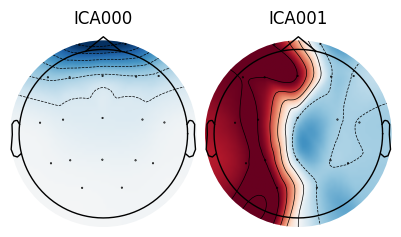

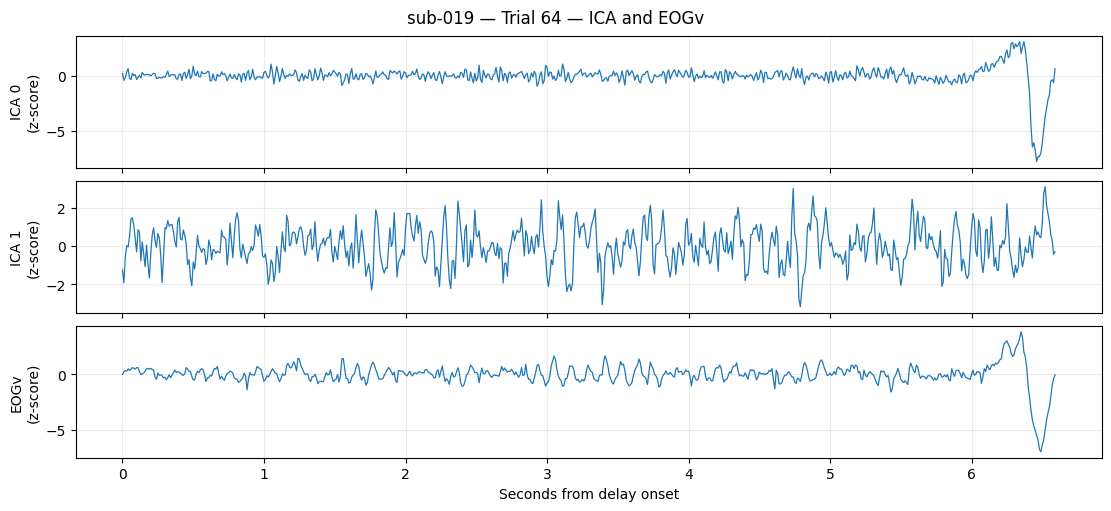


sub-020 — ICA candidates


,component,EOGv_correlation,absolute_correlation
0,0,-0.849,0.849
1,3,-0.096,0.096


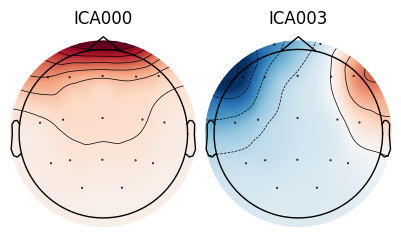

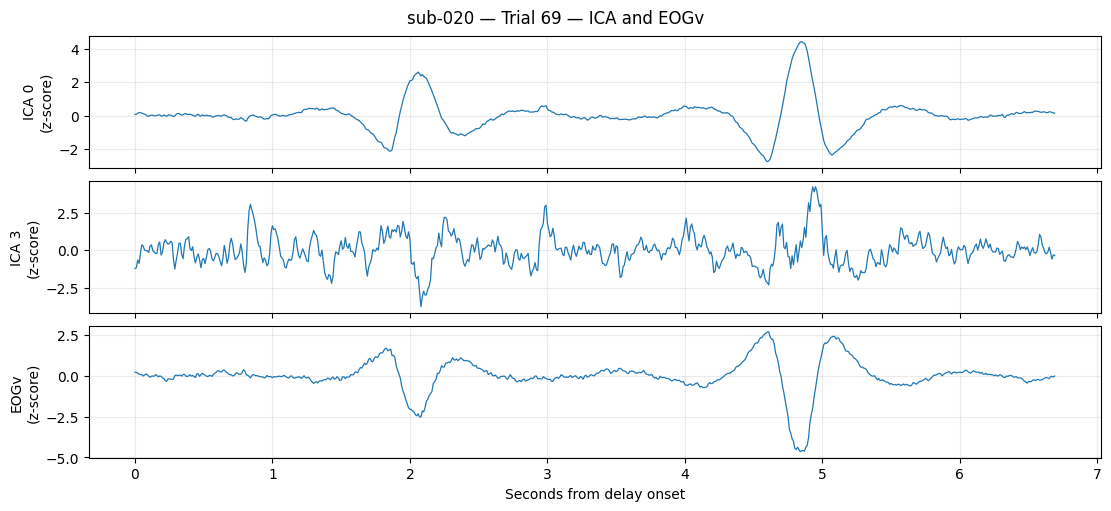


sub-021 — ICA candidates


,component,EOGv_correlation,absolute_correlation
0,0,0.56,0.56
1,5,-0.34,0.34


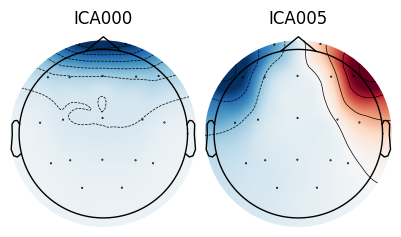

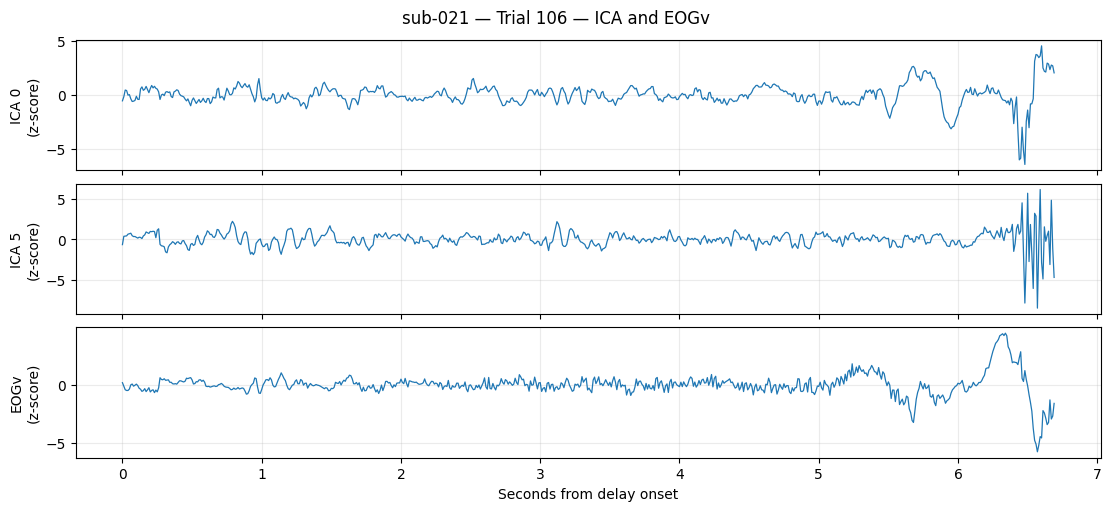


sub-022 — ICA candidates


,component,EOGv_correlation,absolute_correlation
0,0,-0.845,0.845
1,3,0.142,0.142


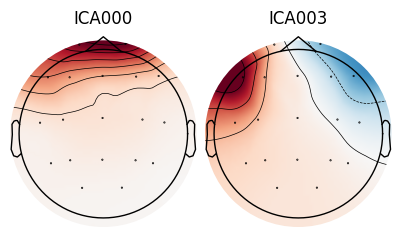

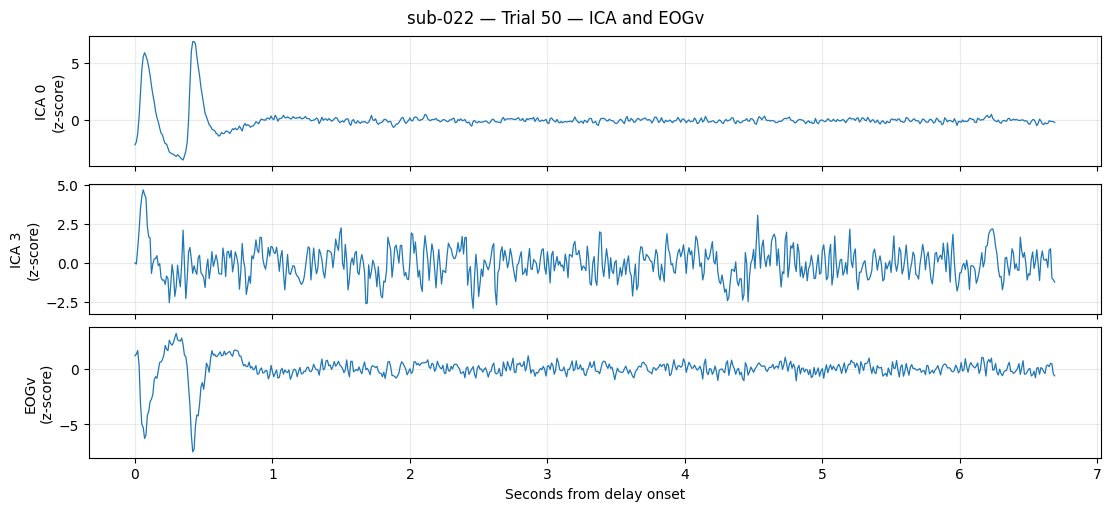


sub-023 — ICA candidates


,component,EOGv_correlation,absolute_correlation
0,0,-0.731,0.731
1,7,0.329,0.329


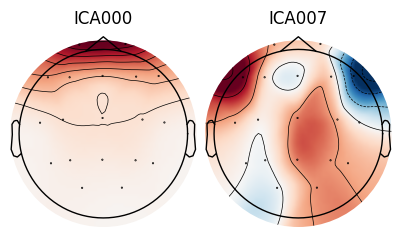

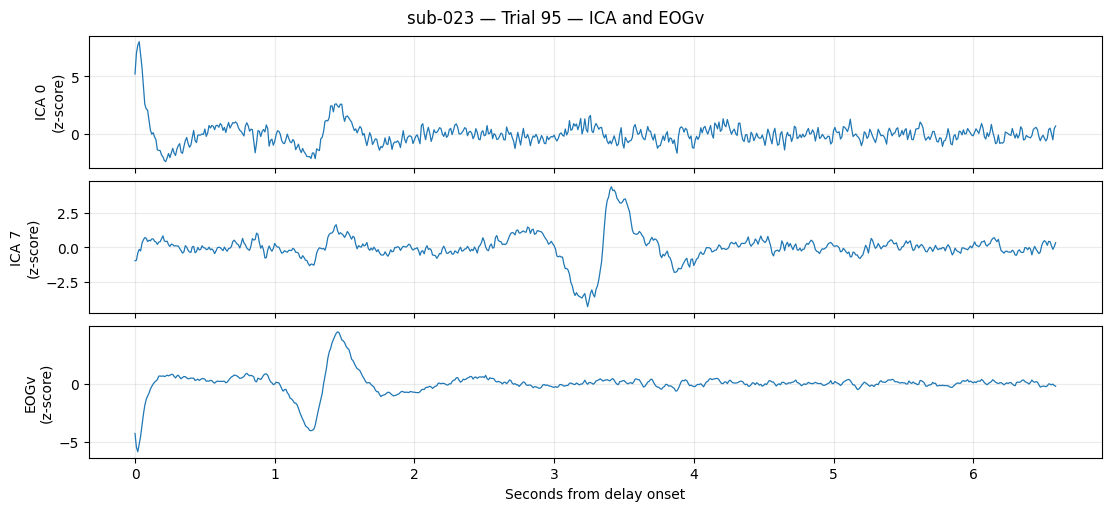


sub-024 — ICA candidates


,component,EOGv_correlation,absolute_correlation
0,0,-0.654,0.654
1,1,-0.173,0.173


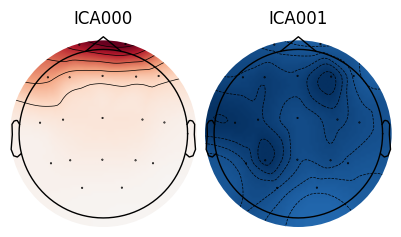

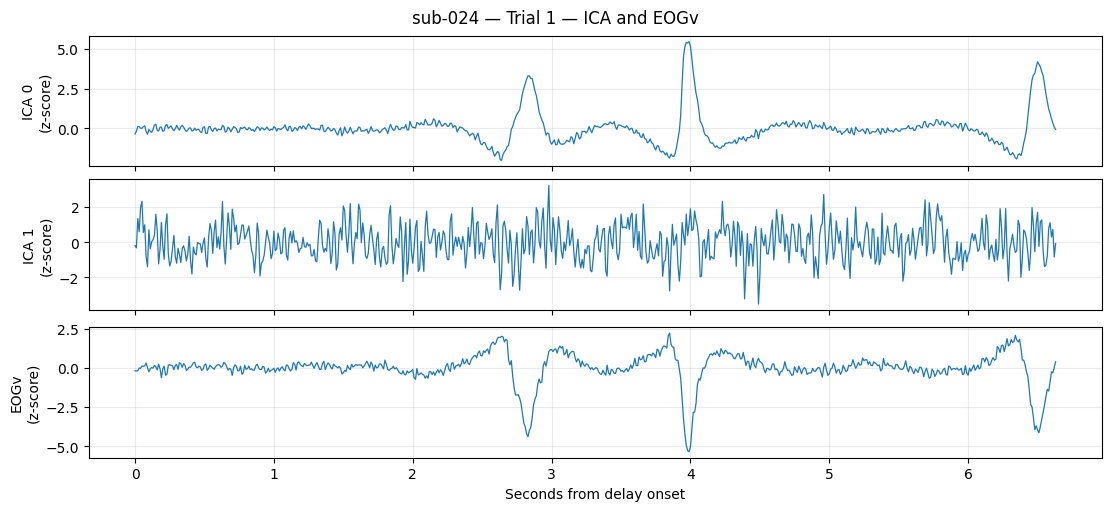

In [34]:
import matplotlib.pyplot as plt
import mne
import numpy as np
import pandas as pd
from IPython.display import display

# participant_ids and batch_dir come from the Setup cell.
trials = pd.read_csv(batch_dir / "batch_trial_table.csv")
if set(trials["participant_id"]) != set(participant_ids):
    raise ValueError("Trial table IDs do not match Setup. Rerun Event Check.")

montage = mne.channels.make_standard_montage("colin27_1020")


def standardize(signal):
    sd = signal.std()
    return (signal - signal.mean()) / sd if sd > 0 else np.zeros_like(signal)


for participant in participant_ids:
    folder = batch_dir / participant
    raw_path = folder / f"{participant}_filtered_raw.fif"
    ica_path = folder / f"{participant}-ica.fif"
    scores_path = folder / "component_scores.csv"
    settings_path = folder / "ica_fit_settings.json"

    if not all(path.is_file() for path in (
        raw_path, ica_path, scores_path, settings_path
    )):
        print(f"{participant}: ICA checkpoint incomplete. Check the fit summary.")
        continue

    raw = mne.io.read_raw_fif(raw_path, preload=False, verbose="ERROR")
    ica = mne.preprocessing.read_ica(ica_path, verbose="ERROR")

    try:
        ranking = pd.read_csv(scores_path)
        candidates = ranking.nlargest(2, "absolute_correlation")
        picks = candidates["component"].astype(int).tolist()

        # Use standard electrode positions for the scalp plots.
        print(f"\n{participant} — ICA candidates")
        display(candidates.round(3))
        ica_plot = ica.copy()
        ica_plot.info.set_montage(montage, match_case=False, on_missing="raise")
        ica_plot.plot_components(picks=picks, show=True)

        fs = raw.info["sfreq"]
        subject_trials = trials.loc[trials["participant_id"].eq(participant)]
        strongest = None

        for trial in subject_trials.itertuples(index=False):
            start = round((trial.delay_onset - raw.first_time) * fs)
            stop = round((trial.probe_onset - raw.first_time) * fs)
            if not 0 <= start < stop <= raw.n_times:
                raise ValueError(
                    f"{participant}: trial {trial.trial_number} outside recording."
                )

            eog = raw.get_data(picks=["EOGv"], start=start, stop=stop)[0]
            eog_range = np.ptp(eog)
            if strongest is None or eog_range > strongest["eog_range"]:
                strongest = {
                    "trial": trial.trial_number,
                    "start": start,
                    "stop": stop,
                    "eog": eog,
                    "eog_range": eog_range,
                }

        sources = ica.get_sources(
            raw, start=strongest["start"], stop=strongest["stop"]
        ).get_data()
        eog = strongest["eog"]
        time = np.arange(len(eog)) / fs

        traces = [(f"ICA {index}", sources[index]) for index in picks]
        traces.append(("EOGv", eog))

        fig, axes = plt.subplots(
            len(traces), 1, figsize=(11, 5), sharex=True, constrained_layout=True
        )
        for ax, (label, signal) in zip(axes, traces):
            ax.plot(time, standardize(signal), linewidth=0.9)
            ax.set_ylabel(f"{label}\n(z-score)")
            ax.grid(alpha=0.25)

        axes[-1].set_xlabel("Seconds from delay onset")
        fig.suptitle(
            f"{participant} — Trial {strongest['trial']} — ICA and EOGv"
        )
        plt.show()
        plt.close(fig)
    finally:
        raw.close()

In [44]:
if False:  # Historical ICA review for sub-010
    from pathlib import Path

    import matplotlib.pyplot as plt
    import mne
    import numpy as np
    import pandas as pd
    from IPython.display import display

    participant = "sub-010"
    review_dir = Path("/content/drive/MyDrive/EEG_Project/checkpoints/batch_sub007_to_sub012")
    folder = review_dir / participant
    trials = pd.read_csv(review_dir / "batch_trial_table.csv")
    subject_trials = trials.loc[trials["participant_id"].eq(participant)]
    assert len(subject_trials) == 120, "Expected 120 trials for sub-010."

    raw = mne.io.read_raw_fif(
        folder / f"{participant}_filtered_raw.fif",
        preload=False, verbose="ERROR",
    )
    ica = mne.preprocessing.read_ica(
        folder / f"{participant}-ica.fif", verbose="ERROR"
    )

    fs = raw.info["sfreq"]
    first_time = raw.first_time
    eog = raw.get_data(picks=["EOGv"])[0]
    component = ica.get_sources(raw).get_data(picks=[0])[0]
    assert len(eog) == len(component) == raw.n_times
    raw.close()


    def zscore(x):
        sd = x.std()
        return (x - x.mean()) / sd if sd > 0 else np.zeros_like(x)


    rows = []
    for trial in subject_trials.itertuples(index=False):
        start = round((trial.delay_onset - first_time) * fs)
        stop = round((trial.probe_onset - first_time) * fs)
        if not 0 <= start < stop <= len(eog):
            raise ValueError(f"Trial {trial.trial_number} is outside the recording.")

        eye = eog[start:stop]
        ic = component[start:stop]
        r = np.corrcoef(ic, eye)[0, 1] if eye.std() > 0 and ic.std() > 0 else np.nan
        rows.append({
            "trial_number": trial.trial_number,
            "eog_ptp_uV": np.ptp(eye) * 1e6,
            "ica0_EOGv_r": r,
            "start": start,
            "stop": stop,
        })

    audit = pd.DataFrame(rows)
    audit.to_csv(folder / "ica0_eogv_delay_review.csv", index=False)

    # Pick by EOGv amplitude before comparing ICA correlations.
    selected = audit.nlargest(3, "eog_ptp_uV")
    display(selected[["trial_number", "eog_ptp_uV", "ica0_EOGv_r"]].round(3))
    print("Median signed r across trials:", round(audit["ica0_EOGv_r"].median(), 3))

    fig, axes = plt.subplots(3, 1, figsize=(11, 7), constrained_layout=True)
    for ax, trial in zip(axes, selected.itertuples(index=False)):
        start, stop = trial.start, trial.stop
        time = np.arange(stop - start) / fs
        ax.plot(time, zscore(eog[start:stop]), label="EOGv")
        ax.plot(time, -zscore(component[start:stop]), label="ICA 0 (flipped)")
        ax.set_title(f"Trial {trial.trial_number} | signed r = {trial.ica0_EOGv_r:.2f}")
        ax.set_ylabel("z-score")
        ax.grid(alpha=0.25)
        ax.legend(loc="upper right")

    axes[-1].set_xlabel("Seconds from delay onset")
    plt.show()
    plt.close(fig)


In [45]:
if False:  # Historical ICA review for sub-004
    from pathlib import Path

    import matplotlib.pyplot as plt
    import mne
    import numpy as np
    import pandas as pd
    from IPython.display import display

    review_dir = Path(
        "/content/drive/MyDrive/EEG_Project/checkpoints/batch_sub003_to_sub006"
    )
    participant = "sub-004"
    folder = review_dir / participant

    trials = pd.read_csv(review_dir / "batch_trial_table.csv")
    subject_trials = (
        trials.loc[trials["participant_id"].eq(participant)]
        .sort_values("trial_number")
        .reset_index(drop=True)
    )
    assert len(subject_trials) == 120

    raw = mne.io.read_raw_fif(
        folder / f"{participant}_filtered_raw.fif",
        preload=False,
        verbose="ERROR",
    )
    ica = mne.preprocessing.read_ica(
        folder / f"{participant}-ica.fif", verbose="ERROR"
    )

    fs = raw.info["sfreq"]
    eog = raw.get_data(picks=["EOGv"])[0]
    component = ica.get_sources(raw).get_data(picks=[0])[0]
    assert len(component) == len(eog) == raw.n_times


    def zscore(signal):
        sd = signal.std()
        return (signal - signal.mean()) / sd if sd > 0 else np.zeros_like(signal)


    rows = []
    for position, trial in enumerate(subject_trials.itertuples(index=False)):
        start = round((trial.delay_onset - raw.first_time) * fs)
        stop = round((trial.probe_onset - raw.first_time) * fs)
        if not 0 <= start < stop <= raw.n_times:
            raise ValueError(f"Trial {trial.trial_number} is outside the recording.")

        eye = eog[start:stop]
        ic = component[start:stop]
        r = (
            np.corrcoef(ic, eye)[0, 1]
            if ic.std() > 0 and eye.std() > 0 else np.nan
        )
        rows.append({
            "trial_number": trial.trial_number,
            "recording_part": ["Early", "Middle", "Late"][position // 40],
            "eog_ptp_uV": np.ptp(eye) * 1e6,
            "ica0_EOGv_r": r,
            "start_sample": start,
            "stop_sample": stop,
        })

    audit = pd.DataFrame(rows)
    audit.to_csv(folder / "ica0_eogv_delay_review.csv", index=False)

    selected = audit.loc[
        audit.groupby("recording_part")["eog_ptp_uV"].idxmax()
    ].sort_values("trial_number")

    display(selected[
        ["recording_part", "trial_number", "eog_ptp_uV", "ica0_EOGv_r"]
    ].round(3))
    print("Median signed r across 120 trials:", round(audit["ica0_EOGv_r"].median(), 3))

    fig, axes = plt.subplots(3, 1, figsize=(11, 7), constrained_layout=True)
    for ax, trial in zip(axes, selected.itertuples(index=False)):
        start, stop = trial.start_sample, trial.stop_sample
        time = np.arange(stop - start) / fs
        ax.plot(time, zscore(eog[start:stop]), label="EOGv", linewidth=1)
        ax.plot(time, -zscore(component[start:stop]), label="ICA 0 (flipped)", linewidth=1)
        ax.set_title(
            f"{trial.recording_part} — trial {trial.trial_number} "
            f"(signed r = {trial.ica0_EOGv_r:.2f})"
        )
        ax.set_ylabel("z-score")
        ax.grid(alpha=0.25)
        ax.legend(loc="upper right")

    axes[-1].set_xlabel("Seconds from delay onset")
    plt.show()
    plt.close(fig)
    raw.close()


In [35]:
import json

import mne
import numpy as np
import pandas as pd
from IPython.display import display

trials = pd.read_csv(batch_dir / "batch_trial_table.csv")

# Decisions apply to these specific ICA fits.
decisions = {
    "sub-019": {"exclude": [0], "retain_reviewed": [1], "review_trials": [64]},
    "sub-020": {"exclude": [0], "retain_reviewed": [3], "review_trials": [69]},
    "sub-021": {"exclude": [0], "retain_reviewed": [5], "review_trials": [106]},
    "sub-022": {"exclude": [0], "retain_reviewed": [3], "review_trials": [50]},
    "sub-023": {"exclude": [0], "retain_reviewed": [7], "review_trials": [95]},
    "sub-024": {"exclude": [0], "retain_reviewed": [1], "review_trials": [1]},
}

if set(decisions) != set(participant_ids):
    raise ValueError("Review decisions do not match the participant IDs in Setup.")
if set(trials["participant_id"]) != set(participant_ids):
    raise ValueError("Trial table IDs do not match Setup. Rerun Event Check.")


def abs_corr(x, y):
    if x.std() == 0 or y.std() == 0:
        return np.nan
    return abs(np.corrcoef(x, y)[0, 1])


rows = []
for participant in participant_ids:
    print(f"{participant}: applying reviewed ICA and checking trials...", flush=True)
    folder = batch_dir / participant
    decision = decisions[participant]
    subject_trials = trials.loc[trials["participant_id"].eq(participant)]

    if len(subject_trials) != 120 or not subject_trials["event_status"].eq("PASS").all():
        raise ValueError(f"{participant}: trial table needs review.")

    before = mne.io.read_raw_fif(
        folder / f"{participant}_filtered_raw.fif", preload=True, verbose="ERROR"
    )
    ica = mne.preprocessing.read_ica(
        folder / f"{participant}-ica.fif", verbose="ERROR"
    )
    ica.exclude = decision["exclude"]
    after = ica.apply(before.copy(), verbose="ERROR")

    eeg_names = [
        name for name, kind in zip(after.ch_names, after.get_channel_types())
        if kind == "eeg"
    ]
    assert len(eeg_names) == 19
    fp1, fp2 = [eeg_names.index(name) for name in ("Fp1", "Fp2")]
    fs = before.info["sfreq"]

    for trial in subject_trials.itertuples(index=False):
        start = round((trial.delay_onset - before.first_time) * fs)
        stop = round((trial.probe_onset - before.first_time) * fs)
        if not 0 <= start < stop <= before.n_times:
            raise ValueError(f"{participant}: trial {trial.trial_number} out of bounds.")

        pre = before.get_data(picks=eeg_names, start=start, stop=stop)
        post = after.get_data(picks=eeg_names, start=start, stop=stop)
        eog = before.get_data(picks=["EOGv"], start=start, stop=stop)[0]
        if not np.isfinite(post).all():
            raise ValueError(f"{participant}: non-finite EEG in trial {trial.trial_number}.")

        post_ptp = np.ptp(post, axis=1) * 1e6
        rows.append({
            "participant_id": participant,
            "trial_number": trial.trial_number,
            "condition": trial.condition,
            "max_ptp_before_uV": np.ptp(pre, axis=1).max() * 1e6,
            "max_ptp_after_uV": post_ptp.max(),
            "largest_channel_after": eeg_names[int(post_ptp.argmax())],
            "Fp1_abs_r_before": abs_corr(pre[fp1], eog),
            "Fp1_abs_r_after": abs_corr(post[fp1], eog),
            "Fp2_abs_r_before": abs_corr(pre[fp2], eog),
            "Fp2_abs_r_after": abs_corr(post[fp2], eog),
            "flat_channels_after": int((post_ptp < 0.1).sum()),
            "over_500uV_after": bool(post_ptp.max() > 500),
            "visual_review_trial": trial.trial_number in decision["review_trials"],
        })

    after.save(
        folder / f"{participant}_cleaned_raw.fif", overwrite=True, verbose="ERROR"
    )
    ica.save(
        folder / f"{participant}_reviewed-ica.fif", overwrite=True, verbose="ERROR"
    )
    (folder / "ica_review_decision.json").write_text(
        json.dumps(decision, indent=2), encoding="utf-8"
    )
    before.close()
    after.close()
    del before, after, ica

audit = pd.DataFrame(rows)
assert len(audit) == expected_trials
assert not audit.duplicated(["participant_id", "trial_number"]).any()

summary = audit.groupby("participant_id").agg(
    trials=("trial_number", "size"),
    median_max_ptp_before_uV=("max_ptp_before_uV", "median"),
    median_max_ptp_after_uV=("max_ptp_after_uV", "median"),
    highest_ptp_after_uV=("max_ptp_after_uV", "max"),
    median_Fp1_abs_r_before=("Fp1_abs_r_before", "median"),
    median_Fp1_abs_r_after=("Fp1_abs_r_after", "median"),
    median_Fp2_abs_r_before=("Fp2_abs_r_before", "median"),
    median_Fp2_abs_r_after=("Fp2_abs_r_after", "median"),
    trials_over_500uV=("over_500uV_after", "sum"),
    flat_channel_windows=("flat_channels_after", "sum"),
)

audit.to_csv(batch_dir / "batch_ica_quality_audit.csv", index=False)
summary.to_csv(batch_dir / "batch_ica_quality_summary.csv")

display(summary.round(3))
print("Review trials from the current batch:")
display(audit.loc[
    audit["visual_review_trial"],
    [
        "participant_id", "trial_number",
        "max_ptp_before_uV", "max_ptp_after_uV",
        "Fp1_abs_r_before", "Fp1_abs_r_after",
        "Fp2_abs_r_before", "Fp2_abs_r_after",
    ],
].round(3))
print(f"Audited {len(audit)} trials. Saved to: {batch_dir}")

sub-019: applying reviewed ICA and checking trials...
sub-020: applying reviewed ICA and checking trials...
sub-021: applying reviewed ICA and checking trials...
sub-022: applying reviewed ICA and checking trials...
sub-023: applying reviewed ICA and checking trials...
sub-024: applying reviewed ICA and checking trials...


,trials,median_max_ptp_before_uV,median_max_ptp_after_uV,highest_ptp_after_uV,median_Fp1_abs_r_before,median_Fp1_abs_r_after,median_Fp2_abs_r_before,median_Fp2_abs_r_after,trials_over_500uV,flat_channel_windows
participant_id,,,,,,,,,,
sub-019,120,156.124,148.453,199.416,0.490,0.347,0.483,0.397,0,0
sub-020,120,83.262,42.335,741.317,0.609,0.432,0.457,0.257,1,0
sub-021,120,86.187,81.757,206.365,0.527,0.354,0.452,0.224,0,0
sub-022,120,69.424,63.101,121.764,0.417,0.217,0.352,0.078,0,0
sub-023,120,142.867,122.550,232.418,0.468,0.333,0.240,0.065,0,0
sub-024,120,222.447,102.017,270.370,0.669,0.249,0.713,0.170,0,0


Review trials from the current batch:


,participant_id,trial_number,max_ptp_before_uV,max_ptp_after_uV,Fp1_abs_r_before,Fp1_abs_r_after,Fp2_abs_r_before,Fp2_abs_r_after
63,sub-019,64,274.538,156.325,0.610,0.159,0.590,0.289
188,sub-020,69,346.672,44.092,0.972,0.065,0.971,0.197
345,sub-021,106,231.400,199.939,0.631,0.607,0.617,0.563
409,sub-022,50,317.467,64.414,0.840,0.205,0.852,0.185
574,sub-023,95,266.157,232.418,0.441,0.776,0.525,0.615
600,sub-024,1,421.615,89.248,0.937,0.134,0.948,0.103


Audited 720 trials. Saved to: /content/drive/MyDrive/EEG_Project/checkpoints/batch_sub019_to_sub024


In [38]:
import mne
import numpy as np
import pandas as pd
from scipy.signal import welch
from IPython.display import display

# checkpoints, batch_dir, participant_ids, and expected_trials come from Setup.
pilot_csv = (
    checkpoints / "sub-001_ICA_restored_20261107_184916_UTC"
    / "eeg_features_cleaned_signal.csv"
)

keys = ["participant_id", "trial_number"]
bands = {"theta": (4, 8), "alpha": (8, 13), "beta": (13, 30)}

trials = pd.read_csv(batch_dir / "batch_trial_table.csv")
quality = pd.read_csv(batch_dir / "batch_ica_quality_audit.csv")
pilot_columns = pd.read_csv(pilot_csv, nrows=0).columns
feature_columns = [name for name in pilot_columns if name.endswith("_power")]

assert len(feature_columns) == 57
assert set(trials["participant_id"]) == set(participant_ids)
assert len(trials) == len(quality) == expected_trials
assert not trials.duplicated(keys).any()
assert not quality.duplicated(keys).any()

rows = []

for participant in participant_ids:
    print(f"Extracting features: {participant}", flush=True)
    raw = mne.io.read_raw_fif(
        batch_dir / participant / f"{participant}_cleaned_raw.fif",
        preload=False,
        verbose="ERROR",
    )

    try:
        eeg_names = [
            name for name, kind in zip(raw.ch_names, raw.get_channel_types())
            if kind == "eeg"
        ]
        expected_features = {
            f"{channel}_{band}_power" for channel in eeg_names for band in bands
        }
        if len(eeg_names) != 19 or expected_features != set(feature_columns):
            raise ValueError(f"{participant}: channel or feature names differ from pilot.")

        fs = raw.info["sfreq"]
        assert fs == 100
        subject_trials = trials.loc[trials["participant_id"].eq(participant)]
        assert len(subject_trials) == 120
        assert subject_trials["event_status"].eq("PASS").all()

        for trial in subject_trials.itertuples(index=False):
            start = round((trial.delay_onset - raw.first_time) * fs)
            stop = round((trial.probe_onset - raw.first_time) * fs)
            if not (0 <= start < stop <= raw.n_times and stop - start >= 2 * fs):
                raise ValueError(
                    f"{participant}: invalid window for trial {trial.trial_number}."
                )

            eeg_uV = raw.get_data(picks=eeg_names, start=start, stop=stop) * 1e6
            frequencies, psd = welch(
                eeg_uV, fs=fs, window="hann", nperseg=int(2 * fs),
                noverlap=int(fs), detrend="constant", scaling="density", axis=-1,
            )

            row = {
                "participant_id": participant,
                "trial_number": trial.trial_number,
                "condition": trial.condition,
                "delay_onset": trial.delay_onset,
                "probe_onset": trial.probe_onset,
                "window_duration_seconds": (stop - start) / fs,
            }
            for band, (low, high) in bands.items():
                mask = (frequencies >= low) & (frequencies <= high)
                power = np.trapezoid(psd[:, mask], x=frequencies[mask], axis=-1)
                for channel, value in zip(eeg_names, power):
                    row[f"{channel}_{band}_power"] = value

            rows.append(row)
    finally:
        raw.close()

quality_columns = {
    "max_ptp_after_uV": "max_ptp_uV",
    "flat_channels_after": "flat_channels",
    "over_500uV_after": "over_500uV_review",
}
features = pd.DataFrame(rows).merge(
    quality[keys + list(quality_columns)].rename(columns=quality_columns),
    on=keys,
    how="left",
    validate="one_to_one",
)

assert set(features.columns) == set(pilot_columns)
features = features.loc[:, pilot_columns]
powers = features[feature_columns].to_numpy()

assert len(features) == expected_trials
assert not features.duplicated(keys).any()
assert np.isfinite(powers).all() and (powers >= 0).all()
assert features[list(quality_columns.values())].notna().all().all()

output = batch_dir / "batch_eeg_features_cleaned_signal.csv"
features.to_csv(output, index=False)

display(features.groupby("participant_id").size().rename("trials").to_frame())
print("Trial rows:", len(features))
print("Band-power features:", len(feature_columns))
print("Missing feature values:", int(features[feature_columns].isna().sum().sum()))
print("Saved to Drive:", output)

Extracting features: sub-019
Extracting features: sub-020
Extracting features: sub-021
Extracting features: sub-022
Extracting features: sub-023
Extracting features: sub-024


,trials
participant_id,
sub-019,120
sub-020,120
sub-021,120
sub-022,120
sub-023,120
sub-024,120


Trial rows: 720
Band-power features: 57
Missing feature values: 0
Saved to Drive: /content/drive/MyDrive/EEG_Project/checkpoints/batch_sub019_to_sub024/batch_eeg_features_cleaned_signal.csv


In [39]:
import json

import numpy as np
import pandas as pd
from IPython.display import display

# checkpoints comes from the Setup cell.
base_dir = checkpoints / "batch_sub003_to_sub006"
base_csv = base_dir / "eeg_features_6_participants.csv"
schema_path = base_dir / "eeg_features_6_participants_schema.json"

# Add each later batch here after its feature extraction is complete.
completed_batches = [
    "batch_sub007_to_sub012",
    "batch_sub013_to_sub018",
    "batch_sub019_to_sub024",
]
keys = ["participant_id", "trial_number"]
base = pd.read_csv(base_csv)
schema = json.loads(schema_path.read_text(encoding="utf-8"))
feature_columns = schema["input_feature_columns"]
condition_mapping = schema["condition_mapping"]
task_type_mapping = schema["task_type_mapping"]
conditions = sorted(condition_mapping, key=condition_mapping.get)

derived_columns = {
    "condition_encoded", "load_level", "task_type", "task_type_encoded",
    "response_audit_status", "response_audit_issues",
}
expected_batch_columns = set(base.columns) - derived_columns
assert len(feature_columns) == 57

tables = [base]
seen_participants = set(base["participant_id"])

for batch_name in completed_batches:
    source = checkpoints / batch_name / "batch_eeg_features_cleaned_signal.csv"
    batch = pd.read_csv(source)

    if set(batch.columns) != expected_batch_columns:
        raise ValueError(f"{batch_name}: columns differ from the pilot schema.")

    new_participants = set(batch["participant_id"])
    overlap = seen_participants & new_participants
    if overlap:
        raise ValueError(f"Participants already included: {sorted(overlap)}")

    if not batch["condition"].isin(conditions).all():
        raise ValueError(f"{batch_name}: unexpected condition labels.")

    batch["condition_encoded"] = batch["condition"].map(condition_mapping)
    batch["load_level"] = batch["condition"].str[0].astype(int)
    batch["task_type"] = batch["condition"].str[1]
    batch["task_type_encoded"] = batch["task_type"].map(task_type_mapping)
    batch["response_audit_status"] = "NOT_AUDITED"
    batch["response_audit_issues"] = ""

    tables.append(batch.loc[:, base.columns])
    seen_participants.update(new_participants)

combined = (
    pd.concat(tables, ignore_index=True)
    .sort_values(keys)
    .reset_index(drop=True)
)

assert not combined.duplicated(keys).any()
assert combined["condition"].isin(conditions).all()
powers = combined[feature_columns].to_numpy()
assert np.isfinite(powers).all() and (powers >= 0).all()

counts = pd.crosstab(combined["participant_id"], combined["condition"]).reindex(
    columns=conditions, fill_value=0
)
assert counts.eq(20).all().all(), "Expected 20 trials per participant and condition."
counts["total_trials"] = counts.sum(axis=1)

n_participants = len(seen_participants)
assert len(combined) == 120 * n_participants

output_dir = checkpoints / "combined_features"
output_dir.mkdir(parents=True, exist_ok=True)
output = output_dir / f"eeg_features_{n_participants}_participants.csv"
combined.to_csv(output, index=False)

(output_dir / f"eeg_features_{n_participants}_participants_schema.json").write_text(
    json.dumps(schema, indent=2), encoding="utf-8"
)

display(counts)
display(combined["response_audit_status"].value_counts().to_frame("trials"))
print("Total rows:", len(combined))
print("Band-power features:", len(feature_columns))
print("Saved to Drive:", output)

condition,5R,6R,7R,5M,6M,7M,total_trials
participant_id,,,,,,,
sub-001,20,20,20,20,20,20,120
sub-002,20,20,20,20,20,20,120
sub-003,20,20,20,20,20,20,120
sub-004,20,20,20,20,20,20,120
sub-005,20,20,20,20,20,20,120
sub-006,20,20,20,20,20,20,120
sub-007,20,20,20,20,20,20,120
sub-008,20,20,20,20,20,20,120
sub-009,20,20,20,20,20,20,120


,trials
response_audit_status,
NOT_AUDITED,2640
PASS,225
REVIEW,15


Total rows: 2880
Band-power features: 57
Saved to Drive: /content/drive/MyDrive/EEG_Project/checkpoints/combined_features/eeg_features_24_participants.csv


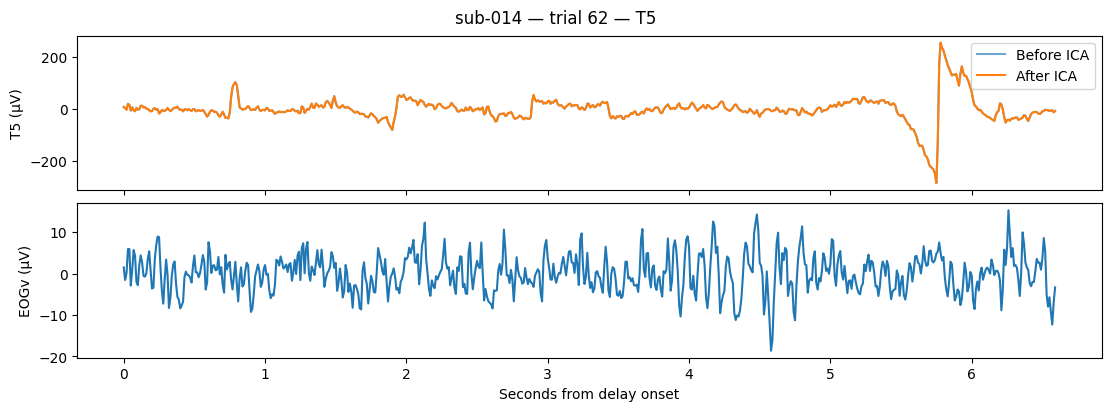

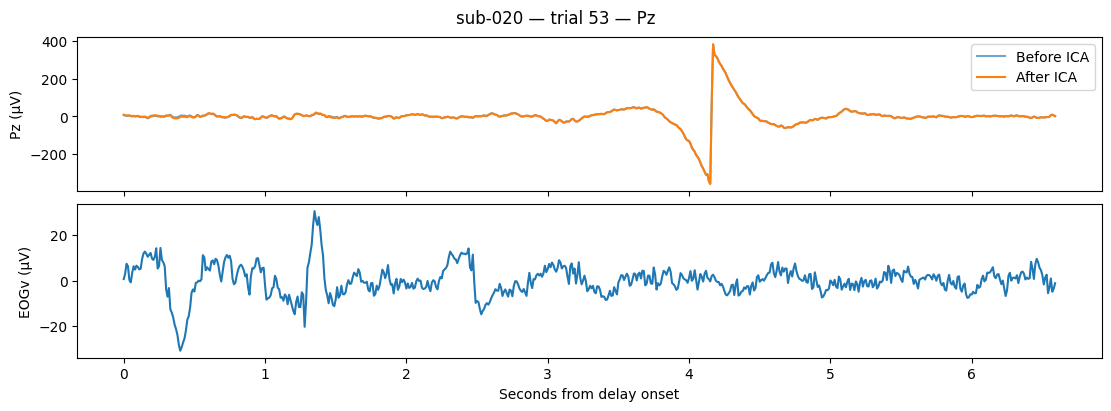

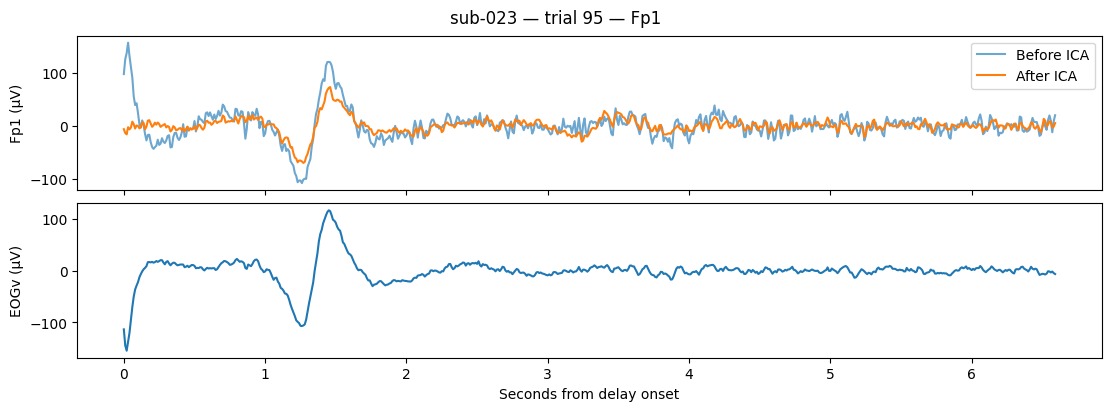

In [40]:
from pathlib import Path

import matplotlib.pyplot as plt
import mne
import numpy as np
import pandas as pd

checkpoints = Path("/content/drive/MyDrive/EEG_Project/checkpoints")
review_batches = [
    ("batch_sub013_to_sub018", "sub-014", None),
    ("batch_sub019_to_sub024", "sub-020", None),
    ("batch_sub019_to_sub024", "sub-023", 95),
]

for batch_name, participant, trial_number in review_batches:
    batch = checkpoints / batch_name
    folder = batch / participant
    audit = pd.read_csv(batch / "batch_ica_quality_audit.csv")
    trials = pd.read_csv(batch / "batch_trial_table.csv")

    selected = audit.loc[audit["participant_id"].eq(participant)]
    if trial_number is None:
        selected = selected.loc[selected["max_ptp_after_uV"].gt(500)]
    else:
        selected = selected.loc[selected["trial_number"].eq(trial_number)]

    if len(selected) != 1:
        raise ValueError(f"{participant}: expected one review trial, found {len(selected)}.")

    entry = selected.iloc[0]
    number = int(entry["trial_number"])
    trial = trials.loc[
        trials["participant_id"].eq(participant) & trials["trial_number"].eq(number)
    ].iloc[0]
    channel = "Fp1" if participant == "sub-023" else entry["largest_channel_after"]

    before = mne.io.read_raw_fif(
        folder / f"{participant}_filtered_raw.fif", preload=False, verbose="ERROR"
    )
    after = mne.io.read_raw_fif(
        folder / f"{participant}_cleaned_raw.fif", preload=False, verbose="ERROR"
    )
    fs = before.info["sfreq"]
    start = round((trial["delay_onset"] - before.first_time) * fs)
    stop = round((trial["probe_onset"] - before.first_time) * fs)
    assert 0 <= start < stop <= before.n_times
    assert before.first_samp == after.first_samp and before.n_times == after.n_times
    time = np.arange(stop - start) / fs

    pre, eog = before.get_data(picks=[channel, "EOGv"], start=start, stop=stop) * 1e6
    post = after.get_data(picks=[channel], start=start, stop=stop)[0] * 1e6
    before.close()
    after.close()

    fig, axes = plt.subplots(2, 1, figsize=(11, 4), sharex=True, constrained_layout=True)
    axes[0].plot(time, pre, label="Before ICA", alpha=0.65)
    axes[0].plot(time, post, label="After ICA")
    axes[0].set_ylabel(f"{channel} (µV)")
    axes[0].legend()
    axes[1].plot(time, eog)
    axes[1].set_ylabel("EOGv (µV)")
    axes[1].set_xlabel("Seconds from delay onset")
    fig.suptitle(f"{participant} — trial {number} — {channel}")
    plt.show()
    plt.close(fig)

In [41]:
from pathlib import Path

import pandas as pd
from IPython.display import display

folder = Path(
    "/content/drive/MyDrive/EEG_Project/checkpoints/combined_features"
)
df = pd.read_csv(folder / "eeg_features_24_participants.csv")

keys = ["participant_id", "trial_number"]
assert len(df) == 2880 and df["participant_id"].nunique() == 24
assert not df.duplicated(keys).any()

review = pd.DataFrame([
    {
        "participant_id": "sub-014",
        "trial_number": 62,
        "signal_qc_note": "Abrupt T5 swing above 500 uV peak-to-peak after ICA",
    },
    {
        "participant_id": "sub-020",
        "trial_number": 53,
        "signal_qc_note": "Abrupt Pz swing above 500 uV peak-to-peak after ICA",
    },
    {
        "participant_id": "sub-023",
        "trial_number": 95,
        "signal_qc_note": "Fp1 amplitude decreased but EOGv correlation increased",
    },
])

excluded = {("sub-014", 62), ("sub-020", 53)}
flagged = set(
    df.loc[df["max_ptp_uV"].gt(500), keys].itertuples(index=False, name=None)
)
assert flagged == excluded, f"Unexpected amplitude flags: {sorted(flagged)}"

annotated = df.merge(review, on=keys, how="left", validate="one_to_one")
assert annotated["signal_qc_note"].notna().sum() == 3

annotated["use_in_primary_analysis"] = ~annotated["max_ptp_uV"].gt(500)
annotated["signal_qc_note"] = annotated["signal_qc_note"].fillna("")

primary_count = int(annotated["use_in_primary_analysis"].sum())
assert primary_count == 2878

output = folder / "eeg_features_24_participants_qc_annotated.csv"
annotated.to_csv(output, index=False)

display(annotated.loc[
    annotated["signal_qc_note"].ne(""),
    keys + ["max_ptp_uV", "use_in_primary_analysis", "signal_qc_note"],
])

print("All trials:", len(annotated))
print("Primary analysis trials:", primary_count)
print("Saved to Drive:", output)

,participant_id,trial_number,max_ptp_uV,use_in_primary_analysis,signal_qc_note
1621,sub-014,62,540.753336,False,Abrupt T5 swing above 500 uV peak-to-peak afte...
2332,sub-020,53,741.317395,False,Abrupt Pz swing above 500 uV peak-to-peak afte...
2734,sub-023,95,232.418455,True,Fp1 amplitude decreased but EOGv correlation i...


All trials: 2880
Primary analysis trials: 2878
Saved to Drive: /content/drive/MyDrive/EEG_Project/checkpoints/combined_features/eeg_features_24_participants_qc_annotated.csv


,primary_trials
condition,
5R,479
6R,480
7R,479
5M,480
6M,480
7M,480


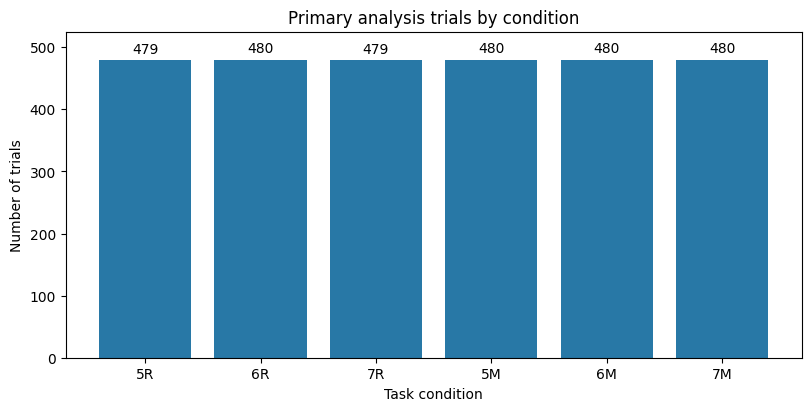

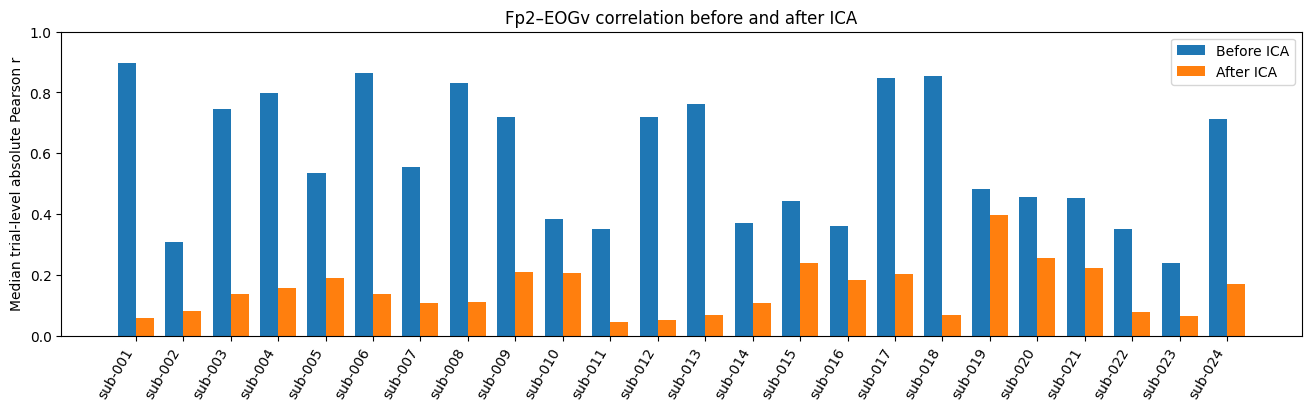

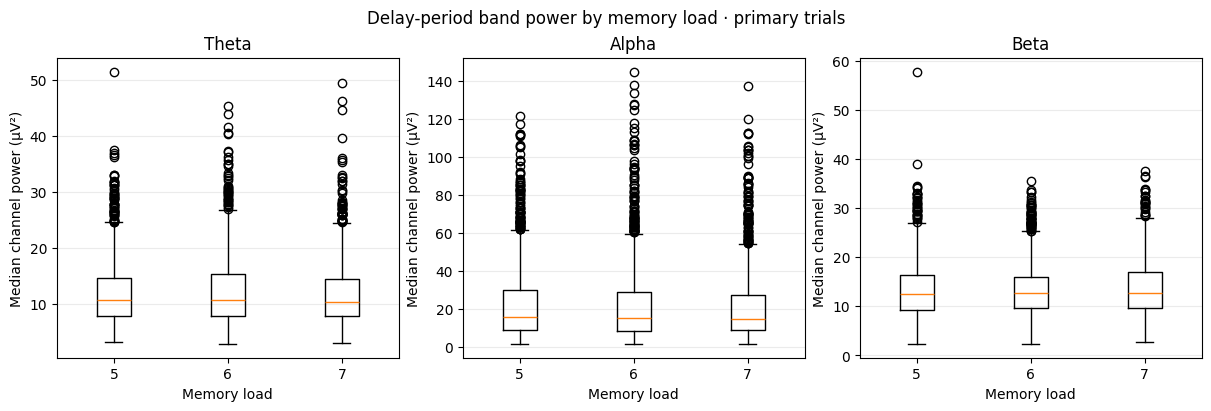

Three figures saved to: /content/drive/MyDrive/EEG_Project/checkpoints/combined_features/cohort_24_figures


In [42]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

checkpoints = Path("/content/drive/MyDrive/EEG_Project/checkpoints")
combined = checkpoints / "combined_features"
figure_dir = combined / "cohort_24_figures"
figure_dir.mkdir(parents=True, exist_ok=True)

df = pd.read_csv(combined / "eeg_features_24_participants_qc_annotated.csv")
primary = df.loc[df["use_in_primary_analysis"].eq(True)].copy()

assert len(df) == 2880
assert len(primary) == 2878 and primary["participant_id"].nunique() == 24


def save_plot(fig, filename):
    fig.savefig(figure_dir / filename, dpi=200, bbox_inches="tight")
    plt.show()
    plt.close(fig)


# 1. Condition balance after signal quality exclusions
conditions = ["5R", "6R", "7R", "5M", "6M", "7M"]
counts = primary["condition"].value_counts().reindex(conditions, fill_value=0)
display(counts.rename("primary_trials").to_frame())

fig, ax = plt.subplots(figsize=(8, 4), constrained_layout=True)
bars = ax.bar(counts.index, counts.values, color="#2878a6")
ax.bar_label(bars, padding=3)
ax.set(
    title="Primary analysis trials by condition",
    xlabel="Task condition",
    ylabel="Number of trials",
    ylim=(0, counts.max() + 45),
)
save_plot(fig, "01_condition_balance.png")

# 2. Median absolute Fp2–EOGv correlation before and after ICA
ica_columns = ["median_Fp2_abs_r_before", "median_Fp2_abs_r_after"]

# Pilot values from the reviewed ICA comparison tables.
pilot_ica = pd.DataFrame(
    [
        ["sub-001", 0.896, 0.059],
        ["sub-002", 0.307, 0.081],
    ],
    columns=["participant_id", *ica_columns],
)

batch_names = [
    "batch_sub003_to_sub006",
    "batch_sub007_to_sub012",
    "batch_sub013_to_sub018",
    "batch_sub019_to_sub024",
]
ica_tables = [pilot_ica]
for name in batch_names:
    summary = pd.read_csv(checkpoints / name / "batch_ica_quality_summary.csv")
    ica_tables.append(summary[["participant_id", *ica_columns]])

ica_summary = pd.concat(ica_tables, ignore_index=True).sort_values("participant_id")
assert len(ica_summary) == 24 and ica_summary["participant_id"].is_unique
assert set(ica_summary["participant_id"]) == set(primary["participant_id"])

x = np.arange(len(ica_summary))
fig, ax = plt.subplots(figsize=(13, 4), constrained_layout=True)
ax.bar(x - 0.19, ica_summary[ica_columns[0]], width=0.38, label="Before ICA")
ax.bar(x + 0.19, ica_summary[ica_columns[1]], width=0.38, label="After ICA")
ax.set_xticks(x, ica_summary["participant_id"], rotation=60, ha="right")
ax.set(
    title="Fp2–EOGv correlation before and after ICA",
    ylabel="Median trial-level absolute Pearson r",
    ylim=(0, 1),
)
ax.legend()
save_plot(fig, "02_ica_before_after.png")

# 3. Band power by load, using the median across 19 channels per trial
fig, axes = plt.subplots(1, 3, figsize=(12, 4), constrained_layout=True)
for ax, band in zip(axes, ["theta", "alpha", "beta"]):
    columns = [column for column in primary if column.endswith(f"_{band}_power")]
    assert len(columns) == 19
    trial_median = primary[columns].median(axis=1)
    ax.boxplot([trial_median.loc[primary["load_level"].eq(load)] for load in (5, 6, 7)])
    ax.set_xticks([1, 2, 3], ["5", "6", "7"])
    ax.set(
        title=band.capitalize(),
        xlabel="Memory load",
        ylabel="Median channel power (µV²)",
    )
    ax.grid(axis="y", alpha=0.25)

fig.suptitle("Delay-period band power by memory load · primary trials")
save_plot(fig, "03_band_power_by_load.png")

print("Three figures saved to:", figure_dir)

In [46]:
if False:  # Historical six-participant merge
    from pathlib import Path
    import json

    import numpy as np
    import pandas as pd
    from IPython.display import display

    checkpoints = Path("/content/drive/MyDrive/EEG_Project/checkpoints")
    pilot_dir = checkpoints / "sub-001_ICA_restored_20261107_184916_UTC"
    historical_batch_dir = checkpoints / "batch_sub003_to_sub006"

    keys = ["participant_id", "trial_number"]
    participants = [f"sub-{number:03d}" for number in range(1, 7)]
    conditions = ["5R", "6R", "7R", "5M", "6M", "7M"]
    condition_mapping = {label: index for index, label in enumerate(conditions)}

    pilot = pd.read_csv(pilot_dir / "eeg_features_cleaned_signal.csv")
    batch = pd.read_csv(historical_batch_dir / "batch_eeg_features_cleaned_signal.csv")

    assert len(pilot) == 240 and len(batch) == 480
    assert list(pilot.columns) == list(batch.columns), "Pilot and batch schemas differ."

    feature_columns = [column for column in pilot.columns if column.endswith("_power")]
    assert len(feature_columns) == 57

    combined = pd.concat([pilot, batch], ignore_index=True)
    assert set(combined["participant_id"]) == set(participants)
    assert not combined.duplicated(keys).any(), "Duplicate participant/trial key."
    assert combined["condition"].isin(conditions).all()

    powers = combined[feature_columns].to_numpy()
    assert np.isfinite(powers).all() and (powers >= 0).all()

    # Reuse the pilot's condition encoding.
    combined["condition_encoded"] = combined["condition"].map(condition_mapping)
    combined["load_level"] = combined["condition"].str[0].astype(int)
    combined["task_type"] = combined["condition"].str[1]
    combined["task_type_encoded"] = combined["task_type"].map({"R": 0, "M": 1})

    # Preserve the pilot response audit and mark the new batch explicitly.
    audit_columns = ["response_audit_status", "response_audit_issues"]
    pilot_audit = pd.read_csv(pilot_dir / "eeg_features_encoded.csv")
    combined = combined.merge(
        pilot_audit[keys + audit_columns],
        on=keys,
        how="left",
        validate="one_to_one",
    )
    pilot_mask = combined["participant_id"].isin(["sub-001", "sub-002"])
    assert combined.loc[pilot_mask, "response_audit_status"].isin(["PASS", "REVIEW"]).all()
    assert combined.loc[~pilot_mask, "response_audit_status"].isna().all()
    combined.loc[~pilot_mask, "response_audit_status"] = "NOT_AUDITED"

    counts = pd.crosstab(
        combined["participant_id"], combined["condition"]
    ).reindex(index=participants, columns=conditions, fill_value=0)
    assert counts.eq(20).all().all()
    counts["total_trials"] = counts.sum(axis=1)

    combined = combined.sort_values(keys).reset_index(drop=True)
    output = historical_batch_dir / "eeg_features_6_participants.csv"
    combined.to_csv(output, index=False)

    schema = {
        "input_feature_columns": feature_columns,
        "condition_mapping": condition_mapping,
        "task_type_mapping": {"R": 0, "M": 1},
        "available_label_columns": ["condition_encoded", "load_level", "task_type_encoded"],
        "band_power_units": "uV^2",
    }
    (historical_batch_dir / "eeg_features_6_participants_schema.json").write_text(
        json.dumps(schema, indent=2), encoding="utf-8"
    )

    display(counts)
    display(combined["response_audit_status"].value_counts().to_frame("trials"))
    print("Total rows:", len(combined))
    print("Band-power features:", len(feature_columns))
    print("Saved to Drive:", output)
